In [22]:
# imports
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import accuracy_score, precision_score, mean_absolute_error, mean_squared_error
from matplotlib import pyplot as plt


# load data from csv
df = pd.read_csv("data/titanic.csv")


In [23]:
# features
X = df[['Sex', 'Fare', 'Age', 'Pclass']].copy()
X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})
X['Age'] = X['Age'].fillna(X['Age'].median())

# target
y = df["Survived"]

In [24]:
# split training data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# choose models
models = [
    LinearRegression(),
    DecisionTreeRegressor(),
    RandomForestRegressor(),
    GradientBoostingRegressor(),
    SVR(),
]

results = {}

for model in models:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_pred_class = y_pred >= 0.5   # survived if prediction >= 0.5
    results[type(model).__name__] = {
        "Accuracy": accuracy_score(y_test, y_pred_class),
        "Precision": precision_score(y_test, y_pred_class),
        "Mean Absolute Error": mean_absolute_error(y_test, y_pred),
        "Mean Squared Error": mean_squared_error(y_test, y_pred),
    }

results = pd.DataFrame(results).T
results


,Accuracy,Precision,Mean Absolute Error,Mean Squared Error
LinearRegression,0.787709,0.757143,0.287746,0.137168
DecisionTreeRegressor,0.770950,0.698795,0.243726,0.227355
RandomForestRegressor,0.793296,0.753425,0.252080,0.155501
GradientBoostingRegressor,0.810056,0.822581,0.257216,0.131899
SVR,0.648045,0.739130,0.360139,0.244040


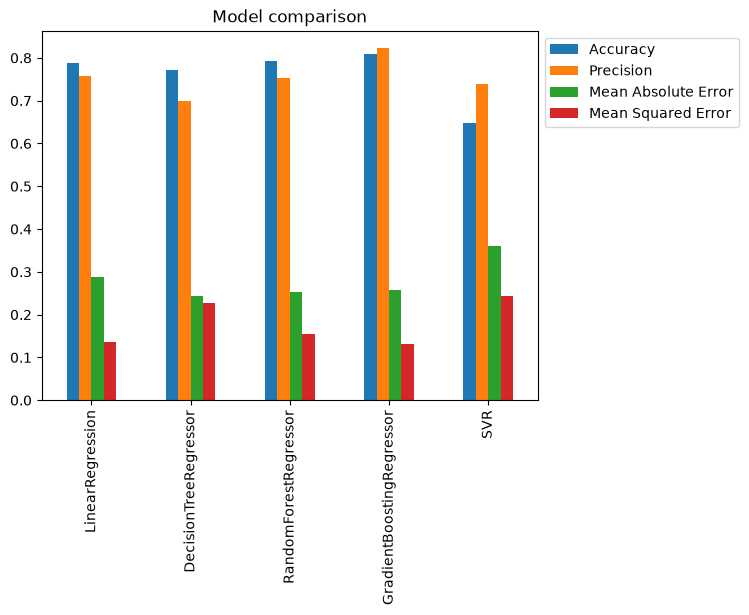

In [25]:
# compare models
results.plot.bar()
plt.title("Model comparison")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()
